# Hinglish sentiment: preprocessing and BiLSTM (Part 2)
This notebook shows the preprocessing and the BiLSTM results. It only **reads saved results**, so it runs in seconds. The code lives in `src/`.
Run it from the `notebooks/` folder.

In [1]:
import json, glob, os
import pandas as pd, matplotlib.pyplot as plt
os.chdir("..")   # go to the repo root so `src` and `results/` are found
from src.data import load_split
from src.preprocess import preprocess_text, PRESETS, tokenize
MODES = ["raw", "clean", "normalized"]

## 1. Preprocessing: three versions of the text
- **raw**: the text exactly as loaded.
- **clean**: URLs and mentions become the placeholders `URL` and `USER`; hashtags and contractions are cleaned. Emojis and negation are kept. Spelling is untouched.
- **normalized**: clean, plus limited repeated letters and a dictionary that maps Hinglish spelling variants (`acha`, `achha`) to one form.

The same function runs on train, dev and test. Nothing is learned from the data.

In [2]:
train = load_split("train")
dev = load_split("dev")
for t in dev["text"].head(4):
    print("original  :", t)
    for m in MODES:
        print(f"{m:11s}:", preprocess_text(t, **PRESETS[m]))
    print()

original  : @ prahladspatel modi mantrimandal may samil honay par badhai narmaday har
raw        : @ prahladspatel modi mantrimandal may samil honay par badhai narmaday har
clean      : USER modi mantrimandal may samil honay par badhai narmaday har
normalized : USER modi mantrimandal may samil honay par badhai narmaday har

original  : @ bkunalraj @ TajinderBagga @ NikhilJakhar14 @ JammuPalchhin @ Shehla _ Rashid @ TajinderBagga Tu toh naamakool hai Mare h … https // t . co / P003zxqUtP
raw        : @ bkunalraj @ TajinderBagga @ NikhilJakhar14 @ JammuPalchhin @ Shehla _ Rashid @ TajinderBagga Tu toh naamakool hai Mare h … https // t . co / P003zxqUtP
clean      : USER Tu toh naamakool hai Mare h URL
normalized : USER Tu toh naamakool hai Mare h URL

original  : @ waglenikhil U saw caste and religion in them ... nation saw talent and trust in them !! .. problem is tum paida hi ulte hue the !!
raw        : @ waglenikhil U saw caste and religion in them ... nation saw talent and trust in 

### Vocabulary size before and after
Counted on the **train** split only. Cleaning removes about 35% of the unique words (mostly mentions, URLs and hashtags). The spelling dictionary then merges only a few hundred more, so the normalizer changes the data very little.

In [3]:
rows = []
for m in MODES:
    toks = [w.lower() for t in train["text"] for w in tokenize(preprocess_text(t, **PRESETS[m]))]
    rows.append({"mode": m, "tokens": len(toks), "unique words": len(set(toks))})
pd.DataFrame(rows)

,mode,tokens,unique words
0,raw,365528,50181
1,clean,272280,32566
2,normalized,272280,32302


## 2. Model
A word embedding (100-d) and a character CNN (kernels 2, 3, 4) are joined for each word. A BiLSTM (128 units, one layer) reads the tweet in both directions. Max and mean pooling give one vector per tweet, and a softmax layer predicts negative, neutral or positive.
The vocabulary is built from train only. Training uses early stopping on dev weighted F1 (patience 4) and 3 seeds (42, 43, 44). Details: `docs/bilstm.md`.

To retrain (about 20 to 35 minutes per seed on CPU):
```
python -m src.train_bilstm --data-root data/raw/zenodo_download/extracted/Semeval_2020_task9_data/Hinglish --mode normalized --seeds 42 43 44
python -m src.train_bilstm --data-root data/raw/zenodo_download/extracted/Semeval_2020_task9_data/Hinglish --mode normalized --seeds 42 43 44 --set use_char=false --run-name bilstm_normalized_wordonly
```

## 3. Dev results (mean ± std over 3 seeds)

In [4]:
def dev_summary(pattern):
    f = sorted(glob.glob(pattern))
    v = [s["metrics"]["weighted_f1"] for p in f for s in json.load(open(p))["per_seed"]]
    return pd.Series(v)

rows = []
for m in MODES:
    s = dev_summary(f"results/bilstm_full_{m}_s*_dev_scores.json")
    rows.append({"model": f"BiLSTM word+char, {m}", "dev weighted F1": f"{s.mean():.4f} ± {s.std():.4f}", "seeds": len(s)})
s = dev_summary("results/bilstm_bilstm_normalized_wordonly_dev_scores.json")
rows.append({"model": "BiLSTM word-only, normalized", "dev weighted F1": f"{s.mean():.4f} ± {s.std():.4f}", "seeds": len(s)})
tf = json.load(open("results/tfidf_dev_scores.json"))
for k in ["word_1-2", "char_2-5", "word+char"]:
    rows.append({"model": f"TF-IDF {k} + logistic regression", "dev weighted F1": f"{tf[k]['best_dev']['weighted_f1']:.4f}", "seeds": 1})
pd.DataFrame(rows)

,model,dev weighted F1,seeds
0,"BiLSTM word+char, raw",0.6105 ± 0.0041,3
1,"BiLSTM word+char, clean",0.6118 ± 0.0015,3
2,"BiLSTM word+char, normalized",0.6071 ± 0.0007,3
3,"BiLSTM word-only, normalized",0.6069 ± 0.0037,3
4,TF-IDF word_1-2 + logistic regression,0.6113,1
5,TF-IDF char_2-5 + logistic regression,0.6127,1
6,TF-IDF word+char + logistic regression,0.6121,1


The differences are within the seed-to-seed spread. The word-only model is not better than word+char, so the character CNN gives no clear gain on this data. TF-IDF scores about the same as the BiLSTM.

## 4. Training curves (word+char and word-only, normalized)

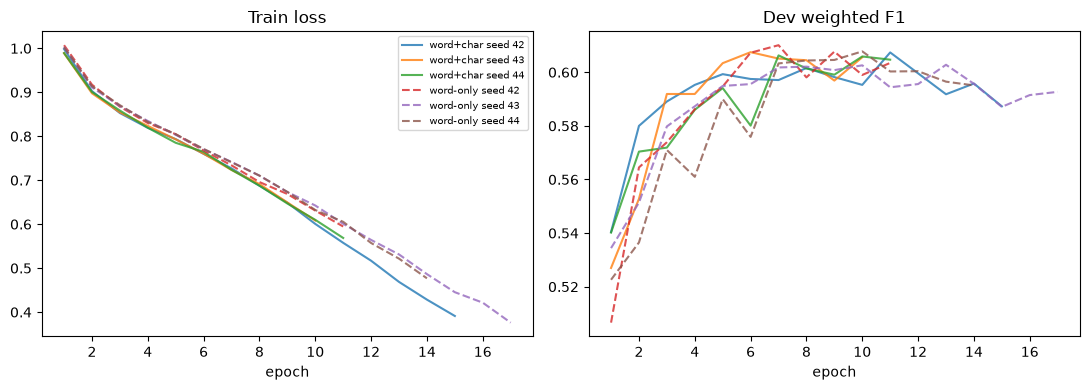

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
runs = {"word+char": "results/bilstm_full_normalized_s*_dev_scores.json",
        "word-only": "results/bilstm_bilstm_normalized_wordonly_dev_scores.json"}
for style, (name, pat) in zip(["-", "--"], runs.items()):
    for p in sorted(glob.glob(pat)):
        for s in json.load(open(p))["per_seed"]:
            e = [h["epoch"] for h in s["history"]]
            ax[0].plot(e, [h["train_loss"] for h in s["history"]], style, label=f"{name} seed {s['seed']}", alpha=.8)
            ax[1].plot(e, [h["dev_weighted_f1"] for h in s["history"]], style, alpha=.8)
ax[0].set(title="Train loss", xlabel="epoch"); ax[1].set(title="Dev weighted F1", xlabel="epoch")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

Train loss keeps falling while dev F1 stops improving after about epoch 7 to 10, which is overfitting. Early stopping keeps the best epoch.

## 5. Final test results (saved; the test set was run once, with frozen checkpoints)

In [6]:
t = json.load(open("results/bilstm_final_test/metrics_summary.json"))
pd.DataFrame([{"mode": m,
               "macro F1": f"{t[m]['macro_f1']['mean']:.4f} ± {t[m]['macro_f1']['std']:.4f}",
               "weighted F1": f"{t[m]['weighted_f1']['mean']:.4f} ± {t[m]['weighted_f1']['std']:.4f}"} for m in MODES])

,mode,macro F1,weighted F1
0,raw,0.6615 ± 0.0077,0.6603 ± 0.0066
1,clean,0.6716 ± 0.0030,0.6681 ± 0.0023
2,normalized,0.6589 ± 0.0061,0.6566 ± 0.0059


Normalization did not help: `clean` is the best on test, `normalized` is the lowest, and the differences are small compared with seed variation. The test scores are about 0.05 above dev for every mode, and the cause is still unexplained. See `results/bilstm_test_analysis/bilstm_final_analysis.md`.